# Параллельные вычисления (1)

__Автор задач: Блохин Н.В. (NVBlokhin@fa.ru)__

Материалы:
* Макрушин С.В. Лекция "Параллельные вычисления"
* https://docs.python.org/3/library/multiprocessing.html
    * https://docs.python.org/3/library/multiprocessing.html#multiprocessing.Process
    * https://docs.python.org/3/library/multiprocessing.html#multiprocessing.pool.Pool
    * https://docs.python.org/3/library/multiprocessing.html#multiprocessing.Queue
* https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
* https://numpy.org/doc/stable/reference/generated/numpy.array_split.html

In [1]:
!pip install py7zr

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----------------- ---------------------- 0.8/1.8 MB 4.2 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 4.3 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import multiprocessing
import gdown
import zipfile
import os
import py7zr
from collections import defaultdict
import time
import matplotlib.pyplot as plt
import seaborn as sns

import dask
import dask.dataframe as dd
import dask.bag as db
import shutil

import multiprocessing
import sys
import subprocess
import seaborn as sns
import os
import shutil
import time
from collections import defaultdict
import dask.dataframe as dd

In [3]:
gdown.download(id='14hv77ddkmpcHeJgZ_lD5hqYtWHvi2zJV', output= 'file.7z', quiet=False)

archive_path = '/content/file.7z'
extract_path = '/content'
os.makedirs(extract_path, exist_ok=True)
with py7zr.SevenZipFile(archive_path, mode='r') as z:
    z.extractall(path=extract_path)
print(f"Archive extracted to {extract_path}")

Downloading...
From (original): https://drive.google.com/uc?id=14hv77ddkmpcHeJgZ_lD5hqYtWHvi2zJV
From (redirected): https://drive.google.com/uc?id=14hv77ddkmpcHeJgZ_lD5hqYtWHvi2zJV&confirm=t&uuid=8f091c18-d237-4821-acc8-5e3919dbbad2
To: c:\Users\jack_\MAIN\ВУЗ\ТОД\15\file.7z
100%|██████████| 210M/210M [00:06<00:00, 30.8MB/s] 


FileNotFoundError: [Errno 2] No such file or directory: '/content/file.7z'

In [10]:
archive_path = 'file.7z'
extract_path = 'C:/Users/jack_/MAIN/ВУЗ/ТОД/15'
os.makedirs(extract_path, exist_ok=True)
with py7zr.SevenZipFile(archive_path, mode='r') as z:
    z.extractall(path=extract_path)
print(f"Archive extracted to {extract_path}")

Archive extracted to C:/Users/jack_/MAIN/ВУЗ/ТОД/15


## Задачи для совместного разбора

1. Посчитайте, сколько раз встречается буква "a" в файлах ["xaa", "xab", "xac", "xad"], используя пул процессов.

In [ ]:
import multiprocessing

files = [f"/content/Тема_Параллельные вычисления (1)/data/{name}.txt" for name in ["xaa", "xab", "xac", "xad"]]

def counting(file):
  with open(file, 'r') as f:
    return f.read().lower().count('a')

with multiprocessing.Pool() as pool:
  results = pool.map(counting, files)

print(sum(results))

2. Посчитайте, сколько раз встречается буква "a" в файлах ["xaa", "xab", "xac", "xad"], используя процессы и очереди.

In [ ]:
import multiprocessing

files = [f"/content/Тема_Параллельные вычисления (1)/data/{name}.txt" for name in ["xaa", "xab", "xac", "xad"]]

def counting(file,q):
  with open(file, 'r') as f:
    a = f.read().lower().count('a')
  q.put(a)

q = multiprocessing.Queue()
processes = []
for file in files:
  p = multiprocessing.Process(target=counting, args=(file,q))
  processes.append(p);p.start()
for p in processes:
  p.join()
results = [q.get() for _ in processes]

print(sum(results))

9265858


## Лабораторная работа 5

__При решении данных задач не подразумевается использования циклов или генераторов Python в ходе работы с пакетами `numpy` и `pandas`, если в задании не сказано обратного. Решения задач, в которых для обработки массивов `numpy` или структур `pandas` используются явные циклы (без согласования с преподавателем), могут быть признаны некорректными и не засчитаны.__

###<p class="task" id="1"></p>

1\. В каждой строке файла `tag_nsteps.csv` хранится информация о тэге рецепта и количестве шагов в этом рецепте в следующем виде:

```
tags,n_steps
hungarian,2
european,6
occasion,4
pumpkin,4
................
```

Всего в исходном файле хранится чуть меньше, чем 71 млн, строк. Разбейте файл `tag_nsteps.csv` на несколько (например, 8) примерно одинаковых по объему файлов c названиями `tag_nsteps_*.csv`, где вместо символа `*` указан номер очередного файла. Каждый файл имеет структуру, аналогичную оригинальному файлу (включая заголовок).

При создании файлов выводите на экран сообщения следующего вида:
`file: <название файла> #rows: <кол-во строк в этом файле>`

__Важно__: здесь и далее вы не можете загружать в память весь исходный файл сразу.

In [3]:
#/content/Тема_Параллельные вычисления (1)/data/tag_nsteps.csv
df = dd.read_csv('Тема_Параллельные вычисления (1)/data/tag_nsteps.csv')
df = df.repartition(npartitions=8)


output_dir = 'Тема_Параллельные вычисления (1)/data/tag_steps'
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)
os.makedirs(output_dir, exist_ok=True)

df.to_csv(output_dir + '/tag_nsteps_*.csv', index=False)


['c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_0.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_1.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_2.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_3.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_4.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_5.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_6.csv',
 'c:\\Users\\jack_\\MAIN\\ВУЗ\\ТОД\\15\\Тема_Параллельные вычисления (1)\\data\\tag_steps\\tag_nsteps_7.csv']

###<p class="task" id="2"></p>

2\. Напишите функцию, которая принимает на вход название файла, созданного в результате решения задачи 1, считает для каждого тэга сумму по столбцу `n_steps` и количество строк c этим тэгом, и возвращает результат в виде словаря. Ожидаемый вид итогового словаря:

```
{
    '1-day-or-more': {'sum': 56616, 'count': 12752},
    '15-minutes-or-less': {'sum': 195413, 'count': 38898},
    '3-steps-or-less': {'sum': 187938, 'count': 39711},
    ....
}
```

Примените данную функцию к каждому файлу, полученному в задании 1, и соберите результат в виде списка словарей. Не используйте параллельных вычислений.

Выведите на экран значение по ключу "30-minutes-or-less" для каждого из словарей.

In [ ]:
def get_tag_sum_count_from_file(file: str) -> dict:
    df=dd.read_csv(file)
    df = df.groupby('tags').agg({'n_steps': ['sum', 'count']})
    df = df.compute()
    df.columns = df.columns.droplevel(0)
    return df.to_dict(orient='index')

dicts = []
dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps'
for file in os.listdir(dir):
  dicts.append(get_tag_sum_count_from_file(dir + '/' + file))
for i in dicts:
  print(i['30-minutes-or-less'])

{'sum': 352508, 'count': 46138}
{'sum': 347722, 'count': 45430}
{'sum': 348281, 'count': 45835}
{'sum': 349418, 'count': 46045}
{'sum': 345059, 'count': 45594}
{'sum': 344681, 'count': 45409}
{'sum': 349279, 'count': 45898}
{'sum': 346257, 'count': 45433}


###<p class="task" id="3"></p>

3\. Напишите функцию, которая объединяет результаты обработки отдельных файлов. Данная функция принимает на вход список словарей, каждый из которых является результатом вызова функции `get_tag_sum_count_from_file` для конкретного файла, и агрегирует эти словари. Не используйте параллельных вычислений.

Процедура агрегации словарей имеет следующий вид:
$$d_{agg}[k] = \{sum: \sum_{i=1}^{n}d_{i}[k][sum], count: \sum_{i=1}^{n}d_{i}[k][count]\}$$
где $d_1, d_2, ..., d_n$- результат вызова функции `get_tag_sum_count_from_file` для конкретных файлов.

Примените данную функцию к результату выполнения задания 2. Выведите на экран результат для тэга "30-minutes-or-less".

In [ ]:
def agg_results(tag_sum_count_list: list) -> dict:
  d=defaultdict(lambda: {'sum':0, 'count':0})
  for d_ in tag_sum_count_list:
    for i in d_:
      d[i]['sum']  +=d_[i]['sum']
      d[i]['count']+=d_[i]['count']
  return d

res = agg_results(dicts)
res['30-minutes-or-less']

{'sum': 2783205, 'count': 365782}

###<p class="task" id="4"></p>

4\. Напишите функцию, которая считает среднее значение количества шагов для каждого тэга в словаре. Используйте решения задач 1-3, чтобы получить среднее значение количества шагов каждого тэга для всего датасета, имея результаты обработки частей датасета и результат их агрегации. Выведите на экран результат для тэга "30-minutes-or-less".

Определите, за какое время задача решается для всего датасета. При замере времени учитывайте время расчета статистики для каждого файла, агрегации результатов и, собственно, вычисления средного. Временем, затрачиваемым на процедуру разбиения исходного файла, можно пренебречь.

In [ ]:
def get_tag_mean_n_steps(tag_sum_count: dict) -> dict:
    # tag_sum_count - результат вызова agg_results
    return {i: tag_sum_count[i]['sum']/tag_sum_count[i]['count'] for i in tag_sum_count}
t3 = time.time()
dicts = []
dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps'
for file in os.listdir(dir):
  dicts.append(get_tag_sum_count_from_file(dir + '/' + file))
print(f'Step 1',time.time()-t3)
res = agg_results(dicts)
print(f'Step 2',time.time()-t3)
res_ = get_tag_mean_n_steps(res)
print(f'Step 3',time.time()-t3)
res_['30-minutes-or-less']

Step 1 30.858917713165283
Step 2 30.861175060272217
Step 3 30.861762285232544


7.608917333275011

###<p class="task" id="5"></p>

5\. Повторите решение задачи 4, распараллелив вызовы функции `get_tag_sum_count_from_file` для различных файлов с помощью `multiprocessing.Pool`. Для обработки каждого файла создайте свой собственный процесс. Выведите на экран результат для тэга "30-minutes-or-less". Определите, за какое время задача решается для всех файлов. При замере времени учитывайте время расчета статистики для каждого файла, агрегации результатов и, собственно, вычисления средного. Временем, затрачиваемым на процедуру разбиения исходного файла можно пренебречь.

In [ ]:
def get_tag_sum_count_from_file_single_thread(file: str) -> dict:
    with dask.config.set(scheduler='single-threaded'):
        df = dd.read_csv(file)
        df_agg = df.groupby('tags').agg({'n_steps': ['sum', 'count']})
        result_df = df_agg.compute()

        result_df.columns = result_df.columns.droplevel(0)
        return result_df.to_dict(orient='index')

In [ ]:
dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps'
l = [dir + '/' + file for file in os.listdir(dir)]
t3 = time.time()
dicts = []
with multiprocessing.Pool() as pool:
  dicts = pool.map(get_tag_sum_count_from_file_single_thread, l)
print(f'Step 1',time.time()-t3)
res = agg_results(dicts)
print(f'Step 2',time.time()-t3)
get_tag_mean_n_steps(res)
print(f'Step 3',time.time()-t3)

Step 1 41.77320146560669
Step 2 41.77828907966614
Step 3 41.779478549957275


###<p class="task" id="6"></p>

6\. Повторите решение задачи 4, распараллелив вычисления функции `get_tag_sum_count_from_file` для различных файлов с помощью `multiprocessing.Process`. Для обработки каждого файла создайте свой собственный процесс. Для обмена данными между процессами используйте `multiprocessing.Queue`.

Выведите на экран результат для тэга "30-minutes-or-less". Определите, за какое время задача решается для всех файлов. При замере времени учитывайте время расчета статистики для каждого файла, агрегации результатов и, собственно, вычисления средного. Временем, затрачиваемым на процедуру разбиения исходного файла можно пренебречь.

In [ ]:
processes = []
q = multiprocessing.Queue()
def get_tag_sum_count_from_file_queue(file,q):
    with dask.config.set(scheduler='single-threaded'):
      df=dd.read_csv(file)
      df = df.groupby('tags').agg({'n_steps': ['sum', 'count']})
      df = df.compute()
      df.columns = df.columns.droplevel(0)
      q.put( df.to_dict(orient='index') )
dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps'
l = [dir + '/' + file for file in os.listdir(dir)]
t3 = time.time()
dicts = []
for i in l:
  p = multiprocessing.Process(target=get_tag_sum_count_from_file_queue, args=(i,q));
  processes.append(p);p.start()
dicts = [q.get() for _ in processes]
for p in processes:p.join()
print(f'Step 1',time.time()-t3)
res = agg_results(dicts)
print(f'Step 2',time.time()-t3)
get_tag_mean_n_steps(res)
print(f'Step 3',time.time()-t3)


Step 1 27.257537126541138
Step 2 27.2590012550354
Step 3 27.259413480758667


###<p class="task" id="7"></p>

7\. Исследуйте, как влияет количество запущенных одновременно процессов на скорость решения задачи. Узнайте количество ядер вашего процессора $K$ (воспользуйтесь функцией `multiprocessing.cpu_count`). Повторите решение задачи 1, разбив исходный файл на $\frac{K}{2}$, $K$ и $2K$ фрагментов. Для каждого из разбиений повторите решение задачи 5. Визуализируйте зависимость времени выполнения кода от количества файлов в разбиении. Сделайте вывод в виде текстового комментария.

In [ ]:
def task_5(K):
  df = dd.read_csv('/content/Тема_Параллельные вычисления (1)/data/tag_nsteps.csv')
  df = df.repartition(npartitions=K)
  output_dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps_task7'
  if os.path.exists(output_dir):
      shutil.rmtree(output_dir)
  os.makedirs(output_dir, exist_ok=True)
  df.to_csv(output_dir + '/tag_nsteps_*.csv', index=False)


  dir = '/content/Тема_Параллельные вычисления (1)/data/tag_steps_task7'
  l = [dir + '/' + file for file in os.listdir(dir)]
  t3 = time.time()
  dicts = []
  with multiprocessing.Pool() as pool:
    dicts = pool.map(get_tag_sum_count_from_file_single_thread, l)
  print(f'Step 1',time.time()-t3)
  res = agg_results(dicts)
  print(f'Step 2',time.time()-t3)
  get_tag_mean_n_steps(res)
  print(f'Step 3',time.time()-t3)
  return time.time()-t3
K  = multiprocessing.cpu_count()
times=[
   task_5(K)
  ,task_5(K//2)
  ,task_5(2*K)
]


Step 1 26.532750844955444
Step 2 26.533685207366943
Step 3 26.533917903900146
Step 1 31.70716619491577
Step 2 31.708285331726074
Step 3 31.708478212356567
Step 1 26.653467178344727
Step 2 26.654911518096924
Step 3 26.65508723258972


K == 2


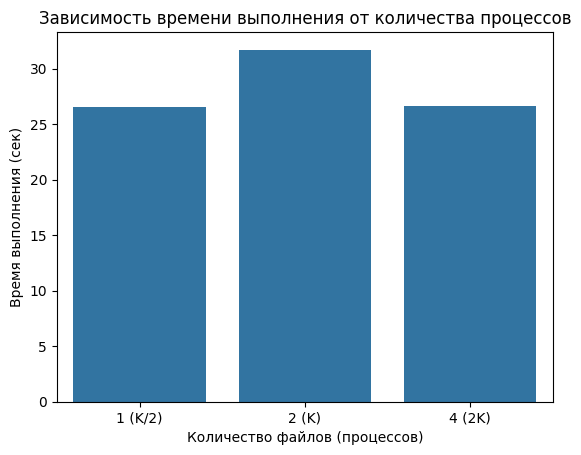

In [ ]:
print(f'K == {K}')
sns.barplot(x=[f'{K//2} (K/2)', f'{K} (K)', f'{2*K} (2K)'], y=times).set(title='Зависимость времени выполнения от количества процессов', xlabel='Количество файлов (процессов)', ylabel='Время выполнения (сек)');

Когда K = 2, то задача является I/O-bound - чтение файлов такого размера очень медленное.

Но, когда  K=4, то чтение файлов поменьше превращает задачу из I/O-bound в среднее между CPU-bound и I/O-bound: время выполнения сопоставимо с временем чтение данных.

In [6]:
worker_code = """
# -*- coding: utf-8 -*-
import dask
import dask.dataframe as dd
import pickle
import sys

def process(file: str) -> dict:
    with dask.config.set(scheduler='single-threaded'):
        df = dd.read_csv(file, encoding='utf-8')
        agg = df.groupby('tags').agg({'n_steps': ['sum', 'count']})
        res = agg.compute()
        res.columns = res.columns.droplevel(0)
        return res.to_dict(orient='index')

if __name__ == '__main__':
    file_path = sys.argv[1]
    result = process(file_path)
    pickle.dump(result, sys.stdout.buffer)
"""
with open("worker.py", "w", encoding='utf-8') as f:
    f.write(worker_code)

runner_code = """
# -*- coding: utf-8 -*-
import sys, os, shutil, time, multiprocessing, subprocess, pickle
import dask.dataframe as dd
from collections import defaultdict

def agg(dicts: list) -> dict:
    valid = [d for d in dicts if d is not None]
    d = defaultdict(lambda: {'sum': 0, 'count': 0})
    for d_ in valid:
        for i in d_:
            d[i]['sum'] += d_[i]['sum']
            d[i]['count'] += d_[i]['count']
    return d

def mean(data: dict) -> dict:
    return {i: data[i]['sum'] / data[i]['count'] for i in data if data[i]['count'] > 0}

def call_worker(file):
    cmd = [sys.executable, 'worker.py', file]
    proc = subprocess.run(cmd, capture_output=True)
    if proc.returncode != 0:
        sys.stderr.buffer.write(proc.stderr)
        return None
    return pickle.loads(proc.stdout)

def run(K: int):
    base = r'/content/Тема_Параллельные вычисления (1)/data'
    input = os.path.join(base, 'tag_nsteps.csv')
    odir = os.path.join(base, f'tag_steps_task7_{K}')

    if not os.path.exists(odir) or not os.listdir(odir):
        if os.path.exists(odir): shutil.rmtree(odir)
        os.makedirs(odir, exist_ok=True)
        df = dd.read_csv(input, encoding='utf-8')
        df = df.repartition(npartitions=K)
        df.to_csv(odir + '/tag_nsteps_*.csv', index=False, encoding='utf-8')

    files = [os.path.join(odir, f) for f in os.listdir(odir)]
    
    t0 = time.time()
    with multiprocessing.Pool() as pool:
        dicts = pool.map(call_worker, files)
    res = agg(dicts)
    mean(res)
    print(time.time() - t0)

if __name__ == '__main__':
    K = int(sys.argv[1])
    run(K)
"""
with open("runner.py", "w", encoding='utf-8') as f:
    f.write(runner_code)

K == 16


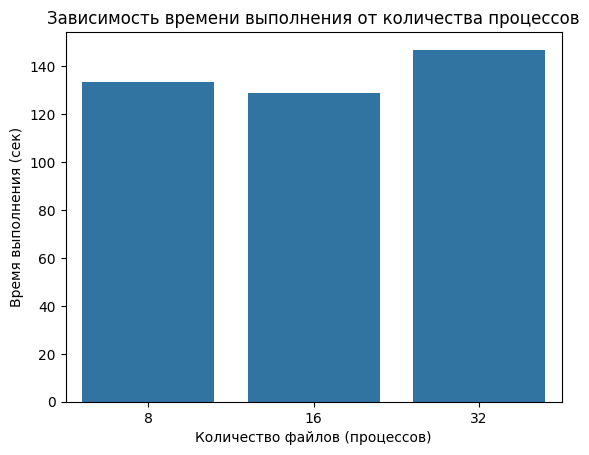

In [7]:
K = multiprocessing.cpu_count()
parts = [p for p in [K // 2, K, 2 * K] if p > 0]
times = []
for p in parts:
    cmd = [sys.executable, 'runner.py', str(p)]
    res = subprocess.run(cmd, capture_output=True, text=True, encoding='utf-8')
    if res.returncode == 0:
        times.append(float(res.stdout.strip()))
    else:
        print(f"Error for {p} processes:\n{res.stderr}")
        times.append(None)

print(f'K == {K}')
labels = [f'{val}' for val in parts]
sns.barplot(x=labels, y=times).set(title='Зависимость времени выполнения от количества процессов', xlabel='Количество файлов (процессов)', ylabel='Время выполнения (сек)');